In [177]:
import pandas as pd
import numpy as np

In [178]:
df=pd.read_csv('data.csv')
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [179]:
df.columns=df.columns.str.lower().str.replace(' ','_')

In [180]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='object')

In [181]:
df.dtypes

make                  object
model                 object
year                   int64
engine_fuel_type      object
engine_hp            float64
engine_cylinders     float64
transmission_type     object
driven_wheels         object
number_of_doors      float64
market_category       object
vehicle_size          object
vehicle_style         object
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [182]:
strings=list(df.dtypes[df.dtypes=='object'].index)#on prend les noms des cols
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [183]:
for col in strings:
    df[col]=df[col].str.lower().str.replace(' ','_')

In [184]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [185]:
df.dtypes

make                  object
model                 object
year                   int64
engine_fuel_type      object
engine_hp            float64
engine_cylinders     float64
transmission_type     object
driven_wheels         object
number_of_doors      float64
market_category       object
vehicle_size          object
vehicle_style         object
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [186]:
#understand teh data 
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
['bmw' 'audi' 'fiat' 'mercedes-benz' 'chrysler']
48

model
['1_series_m' '1_series' '100' '124_spider' '190-class']
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
['premium_unleaded_(required)' 'regular_unleaded'
 'premium_unleaded_(recommended)' 'flex-fuel_(unleaded/e85)' 'diesel']
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
['manual' 'automatic' 'automated_manual' 'direct_drive' 'unknown']
5

driven_wheels
['rear_wheel_drive' 'front_wheel_drive' 'all_wheel_drive'
 'four_wheel_drive']
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
['factory_tuner,luxury,high-performance' 'luxury,performance'
 'luxury,high-performance' 'luxury' 'performance']
71

vehicle_size
['compact' 'midsize' 'large']
3

vehicle_style
['coupe' 'convertible' 'sedan' 'wagon' '4dr_hatchback']
16

highway_mpg
[26 28 27 25 24]
59

city_mpg
[19 20 18 17 16]
69

popularity
[3916 3105  819  617 1013]
48

msrp
[46135 40650 36350 29450 345

In [187]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

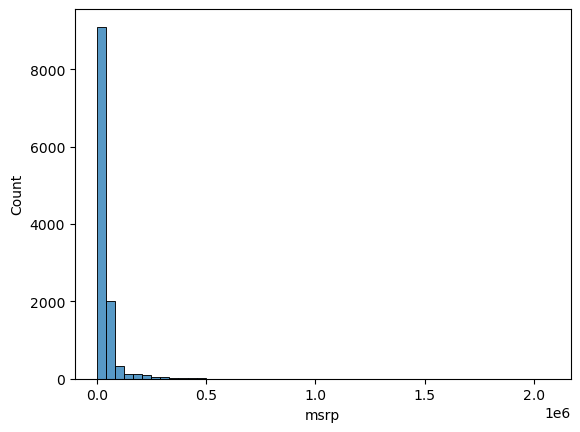

In [188]:
sns.histplot(df.msrp,bins=50)

<Axes: xlabel='msrp', ylabel='Count'>

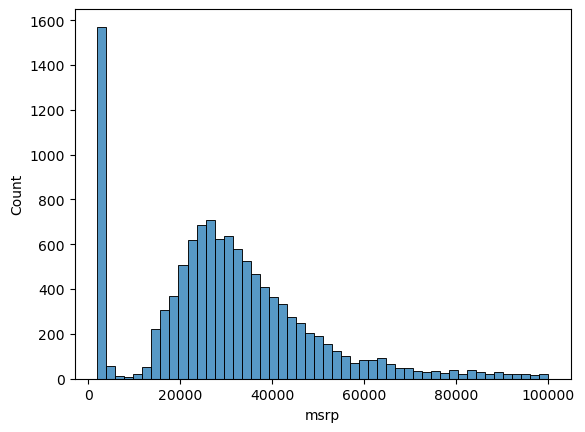

In [189]:
sns.histplot(df.msrp[df.msrp<=100000],bins=50)

In [190]:
price_logs=np.log(df.msrp)

In [191]:
price_logs

0        10.739327
1        10.612754
2        10.500949
3        10.290449
4        10.448715
           ...    
11909    10.739002
11910    10.945000
11911    10.832102
11912    10.838011
11913    10.274879
Name: msrp, Length: 11914, dtype: float64

<Axes: xlabel='msrp', ylabel='Count'>

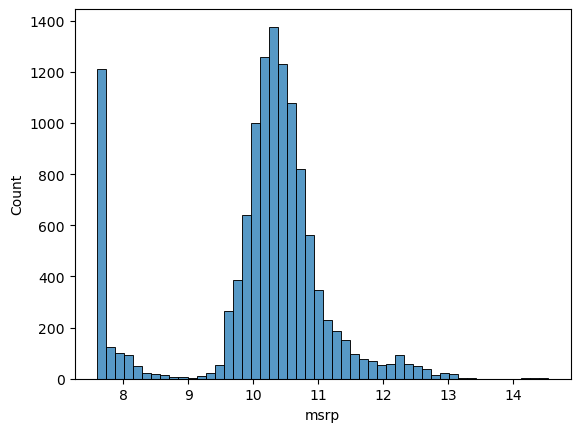

In [192]:
sns.histplot(price_logs,bins=50)

In [193]:
df.isnull().sum()


make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [194]:
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test

In [195]:
n,n_val+n_test,n_train,n_val

(11914, 4764, 7150, 2382)

In [196]:
df.iloc[[0,1,2]]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350


In [197]:
df_train=df[n_train:]
df_val=df.iloc[n_train:n_train+n_val]
df_test=df[n_train+n_val:]


In [198]:
n_train,len(df_train),n_val,len(df_test),n_test,len(df_val)

(7150, 4764, 2382, 2382, 2382, 2382)

In [199]:
idx=np.arange(n)
idx

array([    0,     1,     2, ..., 11911, 11912, 11913], shape=(11914,))

In [200]:
np.random.seed(2)
np.random.shuffle(idx)
idx

array([2735, 6720, 5878, ..., 6637, 2575, 7336], shape=(11914,))

In [201]:

df_train=df.iloc[idx[:n_train]]
df_val=df.iloc[idx[n_train:n_train+n_val]]
df_test=df.iloc[idx[n_train+n_val:]]


In [202]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260


In [203]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [204]:
df_train.msrp

0        14410
1        19685
2        19795
3         2000
4        56260
         ...  
7145     54900
7146     29215
7147     34675
7148    303300
7149     37820
Name: msrp, Length: 7150, dtype: int64

In [205]:
y_train=np.log1p(df_train.msrp.values)
y_val=np.log1p(df_val.msrp.values)
y_test=np.log1p(df_test.msrp.values)

In [206]:
del df_train['msrp']
del df_val['msrp']
del  df_test['msrp']

In [207]:
#linear regression model
df_train.iloc[10]

make                                 rolls-royce
model                     phantom_drophead_coupe
year                                        2015
engine_fuel_type     premium_unleaded_(required)
engine_hp                                  453.0
engine_cylinders                            12.0
transmission_type                      automatic
driven_wheels                   rear_wheel_drive
number_of_doors                              2.0
market_category        exotic,luxury,performance
vehicle_size                               large
vehicle_style                        convertible
highway_mpg                                   19
city_mpg                                      11
popularity                                    86
Name: 10, dtype: object

In [208]:
xi=[453,11,86]#features of row 10 for the example(engine_hp,engine_mpg,popularity)

In [209]:
w0=7.17
w=[0.01,0.04,0.002]

In [210]:
def linear_regression(xi):
    n=len(xi)
    
    prediction=w0
    
    for j in range(n):
        prediction=prediction+w[j]*xi[j]
    return prediction


In [211]:
linear_regression(xi)

12.312

In [212]:
np.expm1(linear_regression(xi))

np.float64(222347.2221101062)

In [213]:
def dot (xi,w):
    n=len(xi)
    res=0.0
    for j in range(n):
        res=res+w[j]*xi[j]
    return res

In [214]:
w_new=[w0]+w
w_new

[7.17, 0.01, 0.04, 0.002]

In [215]:
#session2.6

def linear_regression(xi):
    return w0+dot(xi,w)

In [216]:
linear_regression(xi)

12.312000000000001

In [217]:
xi=[453,11,86]
w0=7.17
w=[0.01,0.04,0.002]
w_new=[w0]+w

In [218]:
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

In [219]:
x=[x1,x2,x10]#c'est une liste ne doit le convertir en tableau numpy pour faire le produit matreciel
x=np.array(x)
x

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])

In [220]:
def linear_regression(x):
    return x.dot(w_new)

In [221]:
#train a model


In [222]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)

In [223]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

In [224]:
def train_linear__regression(X,y):
    ones=np.ones(X.shape[0])
    
    X=np.column_stack([ones,X])
    XtX=X.T.dot(X)
   
    
    XtX_inv = np.linalg.inv(XtX)
    w_full=XtX_inv.dot(X.T).dot(y)
    
    return w_full[0],w_full[1:]

In [225]:
train_linear__regression(X,y)

(np.float64(300.0677669255575), array([-0.22774253, -2.5769413 , -0.02301206]))

In [226]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86


In [227]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='object')

In [228]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [229]:
x_train=df_train[base].values

In [230]:
y_train

array([ 9.57574708,  9.887663  ,  9.89323518, ..., 10.45380308,
       12.62248099, 10.54061978], shape=(7150,))

In [231]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [232]:
x_train=df_train[base].fillna(0).values

In [233]:
w0,w=train_linear__regression(x_train,y_train)

In [234]:
y_pred=w0+x_train.dot(w)

<Axes: ylabel='Count'>

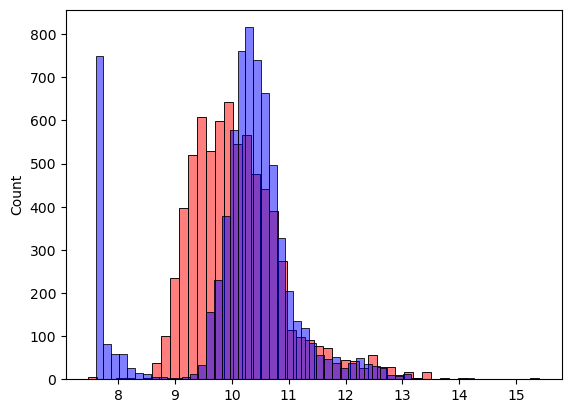

In [235]:
sns.histplot(y_pred,color='red', alpha=0.5, bins=50)
sns.histplot(y_train,color='blue', alpha=0.5, bins=50)

In [236]:
#rmse
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [237]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

In [238]:
X_train = df_train[base].fillna(0).values

In [239]:
def prepare_X(df):#prepare the daat set for the model 
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [240]:
X_train = prepare_X(df_train)
w0, w = train_linear__regression(X_train, y_train)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)
#The number is pretty similar to what we had on the training data. That is what we want to see: the model behaves on unseen data about as well as on the data it learned from. so  its okay 

np.float64(0.7616530991301561)

In [241]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86


In [242]:
df_train.year#2017 l'anne la plus recent du dataset donc on va creer une nouvelle colone age=2017-year

0       2008
1       2012
2       2016
3       1991
4       2017
        ... 
7145    2015
7146    2015
7147    2015
7148    2014
7149    2017
Name: year, Length: 7150, dtype: int64

In [243]:
def prepare_X(df):
    df = df.copy()

    df['age'] = 2017 - df.year
    features = base + ['age']#on a ajouté le age comme une nouvelle feature pour le model

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X


In [244]:
prepare_X(df_train)

array([[1.480e+02, 4.000e+00, 3.300e+01, 2.400e+01, 1.385e+03, 9.000e+00],
       [1.320e+02, 4.000e+00, 3.200e+01, 2.500e+01, 2.031e+03, 5.000e+00],
       [1.480e+02, 4.000e+00, 3.700e+01, 2.800e+01, 6.400e+02, 1.000e+00],
       ...,
       [2.850e+02, 6.000e+00, 2.200e+01, 1.700e+01, 5.490e+02, 2.000e+00],
       [5.630e+02, 1.200e+01, 2.100e+01, 1.300e+01, 8.600e+01, 3.000e+00],
       [2.000e+02, 4.000e+00, 3.100e+01, 2.200e+01, 8.730e+02, 0.000e+00]],
      shape=(7150, 6))

In [245]:
X_train = prepare_X(df_train)
w0, w = train_linear__regression(X_train, y_train)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5172055461058324)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_27356\657581316.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


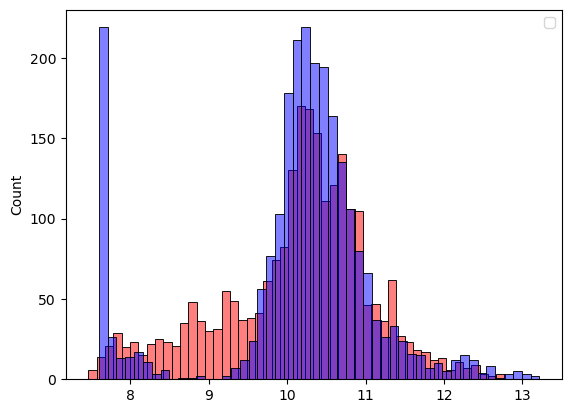

In [246]:
sns.histplot(y_pred,color='red',alpha=0.5, bins=50)
sns.histplot(y_val,color='blue',alpha=0.5, bins=50)
plt.legend()

In [247]:
(df_train.number_of_doors==2).astype('int')

0       1
1       0
2       0
3       0
4       0
       ..
7145    1
7146    1
7147    0
7148    0
7149    0
Name: number_of_doors, Length: 7150, dtype: int64

In [248]:
for v in [2,3,4]:
    df_train['number_doors_%s' %v]=(df_train.number_of_doors==v).astype('int')


In [249]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,number_doors_2,number_doors_3,number_doors_4
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,1,0,0
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,0,0,1
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,0,0,1
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,0,1,0
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,0,0,1


In [250]:
def prepare_X(df):
    df = df.copy()
    features=base.copy()#ne pas modify els noms du base par le append donc on va faire une copie de la liste base
    #ajoute le colonne age pour améloirer le model
    df['age'] = 2017 - df.year
    features.append('age')#on a ajouté le age comme une nouvelle feature pour le model
    
    #ajoute le colonne number od doors pour 2 ,3 et 4 dpuis le colonne number of doors
    for v in [2,3,4]:
        df['number_doors_%s' %v]=(df.number_of_doors==v).astype('int')
        features.append('number_doors_%s' %v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [251]:
prepare_X(df_train)

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [285.,   6.,  22., ...,   0.,   0.,   1.],
       [563.,  12.,  21., ...,   0.,   0.,   1.],
       [200.,   4.,  31., ...,   0.,   0.,   1.]], shape=(7150, 9))

In [252]:
X_train = prepare_X(df_train)
w0, w = train_linear__regression(X_train, y_train)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5157995641502352)

In [253]:
df.make

0            bmw
1            bmw
2            bmw
3            bmw
4            bmw
          ...   
11909      acura
11910      acura
11911      acura
11912      acura
11913    lincoln
Name: make, Length: 11914, dtype: object

In [254]:
df.make.nunique()

48

In [255]:
makes=list(df.make.value_counts().head().index)
makes

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']

In [256]:
def prepare_X(df):
    df = df.copy()
    features=base.copy()#ne pas modify els noms du base par le append donc on va faire une copie de la liste base
    #ajoute le colonne age pour améloirer le model
    df['age'] = 2017 - df.year
    features.append('age')#on a ajouté le age comme une nouvelle feature pour le model
    
    #ajoute le colonne number od doors pour 2 ,3 et 4 dpuis le colonne number of doors
    for v in [2,3,4]:
        df['number_doors_%s' %v]=(df.number_of_doors==v).astype('int')
        features.append('number_doors_%s' %v)
    for v in makes:
        df['make_%s' %v]=(df.make==v).astype('int')
        features.append('make_%s' %v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [257]:
X_train = prepare_X(df_train)
w0, w = train_linear__regression(X_train, y_train)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5076038849557032)

In [ ]:
categorical_variables =list [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

categories = {}

for c in categorical_variables:
    categories[c] = list(df_train[c].value_counts().head().index)

In [259]:
categories

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'hatchback',
  'luxury,performance'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [260]:
def prepare_X(df):
    df = df.copy()
    features=base.copy()#ne pas modify els noms du base par le append donc on va faire une copie de la liste base
    #ajoute le colonne age pour améloirer le model
    df['age'] = 2017 - df.year
    features.append('age')#on a ajouté le age comme une nouvelle feature pour le model
    
    #ajoute le colonne number od doors pour 2 ,3 et 4 dpuis le colonne number of doors
    for v in [2,3,4]:
        df['number_doors_%s' %v]=(df.number_of_doors==v).astype('int')
        features.append('number_doors_%s' %v)
    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [261]:
X_train = prepare_X(df_train)
w0, w = train_linear__regression(X_train, y_train)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(50.33369424418199)

In [262]:
#regalarization
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5],
]
X=np.array(X)
X

array([[4, 4, 4],
       [3, 5, 5],
       [5, 1, 1],
       [5, 4, 4],
       [7, 5, 5],
       [4, 5, 5]])

In [263]:
XTX=X.T.dot(X)

In [264]:
np.linalg.inv(XTX)

LinAlgError: Singular matrix

In [ ]:
def train_linear__regression_reg(X,y,r=0.001):
    ones=np.ones(X.shape[0])
    
    X=np.column_stack([ones,X])
    XtX=X.T.dot(X)
   
   
    
    XtX_inv = np.linalg.inv(XtX)
    w_full=XtX_inv.dot(X.T).dot(y)
    
    return w_full[0],w_full[1:]

In [ ]:
X_train = prepare_X(df_train)
w0, w = train_linear__regression_reg(X_train, y_train,r=0.01)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.456521990129513)

In [ ]:
for r in [0.0, 0.00001, 0.0001, 0.001, 0.01,1,10]:

    X_train = prepare_X(df_train)
    w0, w = train_linear__regression_reg(X_train, y_train,r=r)#le poids doit etre calculer que dans les donnes d'entranements 60%

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score=rmse(y_val, y_pred)
    
    print(r,w0, score)

0.0 -4385683742668581.5 50.33369424418199
1e-05 8.356193526437128 0.45651704110014846
0.0001 6.2274933923199125 0.4565170627781918
0.001 6.286296964119915 0.45651750887938797
0.01 6.276605451676936 0.456521990129513
1 5.634896668388998 0.4572204317996368
10 4.283980108973523 0.47014569320977306


In [ ]:
r=0.001

X_train = prepare_X(df_train)
w0, w = train_linear__regression_reg(X_train, y_train,r=r)#le poids doit etre calculer que dans les donnes d'entranements 60%

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
score=rmse(y_val, y_pred)
    
score

np.float64(0.45651750887938797)

In [ ]:
#using the model
df_full_train=pd.concat([df_train,df_val])

In [ ]:
df_full_train=df_full_train.reset_index(drop=True)

In [ ]:
X_full_train=prepare_X(df_full_train)

In [ ]:
X_full_train

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [332.,   8.,  23., ...,   0.,   0.,   0.],
       [148.,   4.,  34., ...,   0.,   0.,   0.],
       [290.,   6.,  25., ...,   0.,   0.,   0.]], shape=(9532, 41))

In [ ]:
y_full_train=np.concatenate([y_train,y_val])

In [ ]:

w0, w = train_linear__regression_reg(X_full_train, y_full_train,r=0.001)

In [ ]:
w

array([ 1.52506330e-03,  1.18188701e-01, -6.66105622e-03, -5.33414086e-03,
       -4.87603196e-05, -9.69091846e-02, -7.92622583e-01, -8.90863794e-01,
       -6.35102506e-01, -4.14339205e-02,  1.75560740e-01, -5.78066078e-04,
       -1.00563873e-01, -9.27549665e-02, -4.66859099e-01,  7.98659857e-02,
       -3.16047646e-01, -5.51981619e-01, -7.89525245e-02,  1.09536293e+00,
        9.20055382e-01,  1.14963278e+00,  2.65276884e+00,  5.09991980e-01,
        1.62935509e+00,  1.53005914e+00,  1.61723786e+00,  1.54523725e+00,
       -9.70559800e-02,  3.73062090e-02, -5.81767461e-02, -1.19357008e-02,
       -2.35940813e-02,  2.18895262e+00,  2.07458271e+00,  2.05916686e+00,
       -5.00802769e-02,  5.62184639e-02,  1.84794024e-01,  3.32646151e-01,
       -1.58817038e-01])

In [ ]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score=rmse(y_test, y_pred)
    
score

np.float64(0.4517749306915374)

In [ ]:
car=df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

In [ ]:
df_small=pd.DataFrame([car])

In [ ]:
X_small=prepare_X(df_small)

In [ ]:
y_pred = w0 + X_small.dot(w)
y_pred=y_pred[0]
y_pred

np.float64(10.462651700050063)

In [ ]:
np.expm1x(y_pred)

np.float64(34983.19615434434)

In [ ]:
np.expm1x(y_test[20])

np.float64(35000.00000000001)